# Predicting Acceptance of Personal Loans
**UE24CS352A – Machine Learning Mini Project**

Binary classification: will a Thera Bank liability customer accept a personal loan offer (`Personal Loan` = 1)?

Reference: *Prediction of Personal Loan Acceptance using Machine Learning* (paper shared by faculty).
Dataset: Kaggle – [Personal Loan Modeling](https://www.kaggle.com/datasets/teertha/personal-loan-modeling) (5000 customers, 14 columns).

**Notebook flow:** 1) EDA → 2) Preprocessing → 3) Baseline (paper replication) → 4) Improved models → 5) Comparison & conclusions

In [1]:
import sys, warnings
from pathlib import Path
sys.path.append(str(Path.cwd().parent / 'src'))
warnings.filterwarnings('ignore')

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image, display
from preprocess import load_data, clean_data, split_xy, train_test, TARGET

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 20)

## 1. Exploratory Data Analysis

In [2]:
df = load_data()
print(df.shape)
df.head()

(5000, 14)


,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  5000 non-null   int64  
 1   Age                 5000 non-null   int64  
 2   Experience          5000 non-null   int64  
 3   Income              5000 non-null   int64  
 4   ZIP Code            5000 non-null   int64  
 5   Family              5000 non-null   int64  
 6   CCAvg               5000 non-null   float64
 7   Education           5000 non-null   int64  
 8   Mortgage            5000 non-null   int64  
 9   Personal Loan       5000 non-null   int64  
 10  Securities Account  5000 non-null   int64  
 11  CD Account          5000 non-null   int64  
 12  Online              5000 non-null   int64  
 13  CreditCard          5000 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 547.0 KB


In [4]:
print('Missing values:', df.isnull().sum().sum())
print('Duplicate rows:', df.duplicated().sum())
df.describe().T

Missing values: 0
Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
ID,5000.0,2500.500000,1443.520003,1.0,1250.75,2500.5,3750.25,5000.0
Age,5000.0,45.338400,11.463166,23.0,35.00,45.0,55.00,67.0
Experience,5000.0,20.104600,11.467954,-3.0,10.00,20.0,30.00,43.0
Income,5000.0,73.774200,46.033729,8.0,39.00,64.0,98.00,224.0
ZIP Code,5000.0,93152.503000,2121.852197,9307.0,91911.00,93437.0,94608.00,96651.0
Family,5000.0,2.396400,1.147663,1.0,1.00,2.0,3.00,4.0
CCAvg,5000.0,1.937938,1.747659,0.0,0.70,1.5,2.50,10.0
Education,5000.0,1.881000,0.839869,1.0,1.00,2.0,3.00,3.0
Mortgage,5000.0,56.498800,101.713802,0.0,0.00,0.0,101.00,635.0
Personal Loan,5000.0,0.096000,0.294621,0.0,0.00,0.0,0.00,1.0


### 1.1 Class balance
Only ~9.6% of customers accepted the loan → **imbalanced**. A model predicting "No" for everyone already gets ~90% accuracy, so accuracy alone is misleading. We report precision, recall, F1 and ROC-AUC.

Personal Loan
0    4520
1     480
Name: count, dtype: int64 
Positive rate: 9.60%


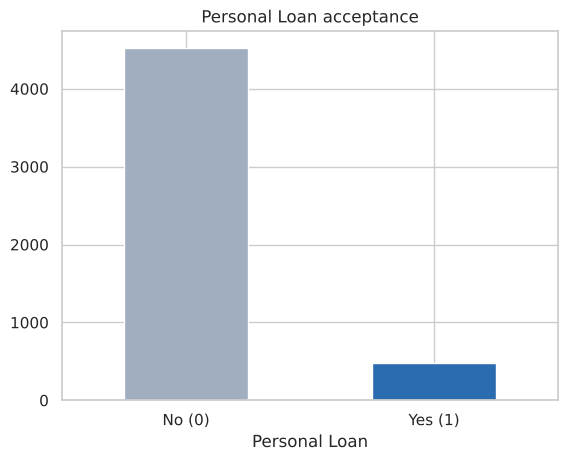

In [5]:
counts = df[TARGET].value_counts()
print(counts, '\nPositive rate: %.2f%%' % (100 * counts[1] / len(df)))
ax = counts.plot.bar(color=['#a0aec0', '#2b6cb0'])
ax.set_xticklabels(['No (0)', 'Yes (1)'], rotation=0); ax.set_title('Personal Loan acceptance'); plt.show()

### 1.2 Data quality issues

In [6]:
print('Negative Experience values:', (df['Experience'] < 0).sum())
print(df.loc[df['Experience'] < 0, 'Experience'].value_counts())
print('Unique ZIP codes:', df['ZIP Code'].nunique())
print('Corr(Age, Experience) = %.3f' % df['Age'].corr(df['Experience']))

Negative Experience values: 52
Experience
-1    33
-2    15
-3     4
Name: count, dtype: int64
Unique ZIP codes: 467
Corr(Age, Experience) = 0.994


- **Experience** has 52 negative values → data-entry errors, clipped to 0.
- **ZIP Code** has ~467 unique values with no ordinal meaning → dropped (noise). **ID** is an identifier → dropped.
- **Age** and **Experience** are ~99% correlated (redundant). Kept both; tree models are unaffected and it doesn't hurt the others noticeably.

### 1.3 Distributions of continuous features by class

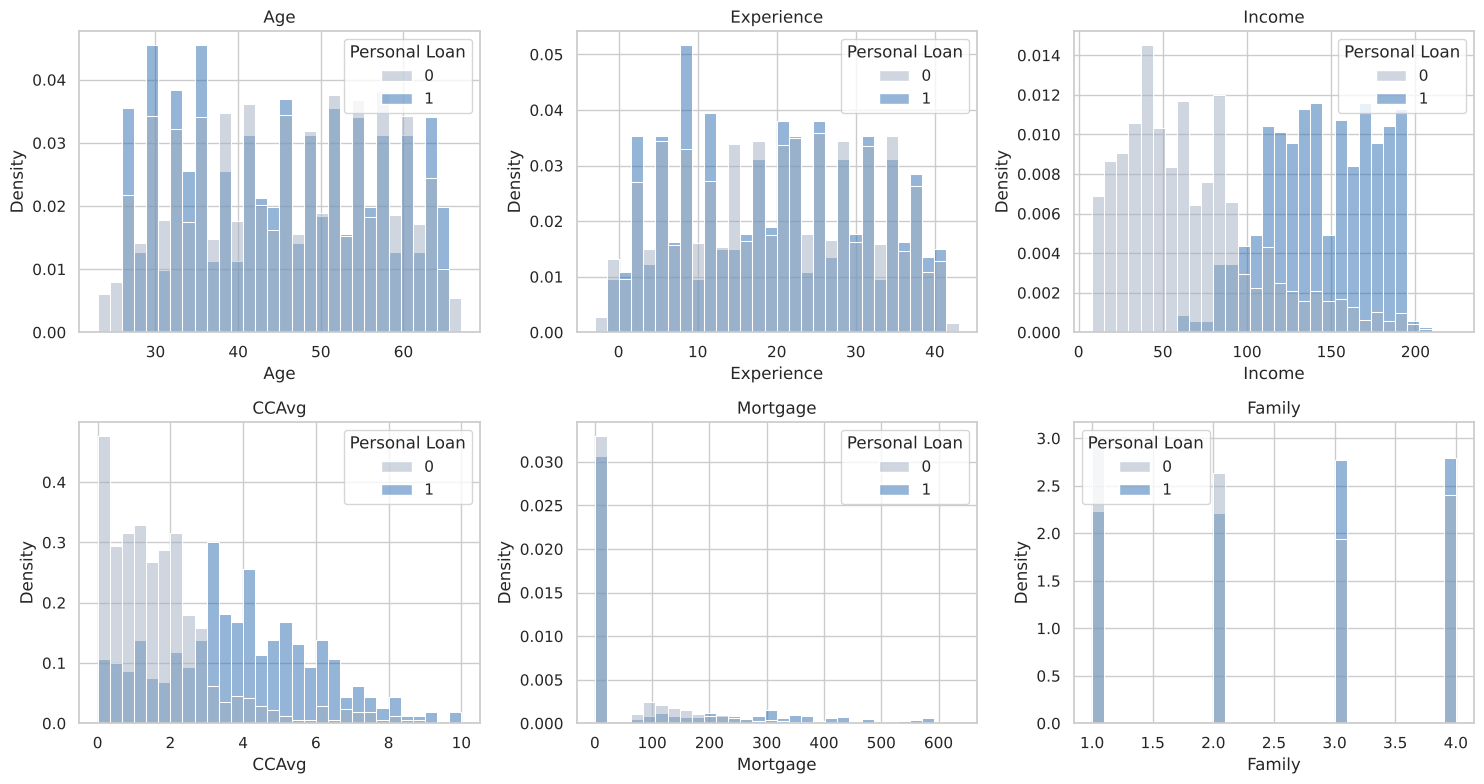

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), ['Age', 'Experience', 'Income', 'CCAvg', 'Mortgage', 'Family']):
    sns.histplot(data=df, x=col, hue=TARGET, bins=30, stat='density', common_norm=False, ax=ax, palette=['#a0aec0', '#2b6cb0'])
    ax.set_title(col)
plt.tight_layout(); plt.show()

**Observation:** acceptors have clearly higher **Income** and **CCAvg** (credit-card spend). Age/Experience distributions look almost identical for both classes.

### 1.4 Acceptance rate by categorical features

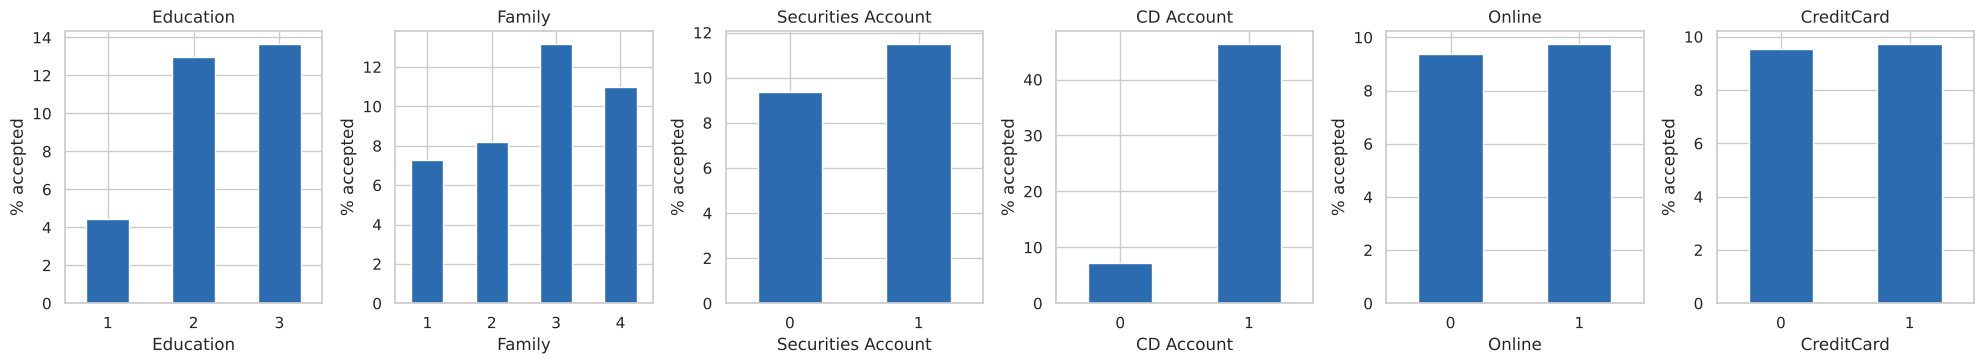

In [8]:
fig, axes = plt.subplots(1, 6, figsize=(20, 3.8))
for ax, col in zip(axes, ['Education', 'Family', 'Securities Account', 'CD Account', 'Online', 'CreditCard']):
    (df.groupby(col)[TARGET].mean() * 100).plot.bar(ax=ax, color='#2b6cb0')
    ax.set_title(col); ax.set_ylabel('% accepted'); ax.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

**Observation:** customers with a **CD Account** accept far more often (~46% vs ~7%). Graduate/professional **Education** (2, 3) and larger **Family** (3, 4) also raise acceptance. Online / CreditCard barely matter.

### 1.5 Correlation heatmap

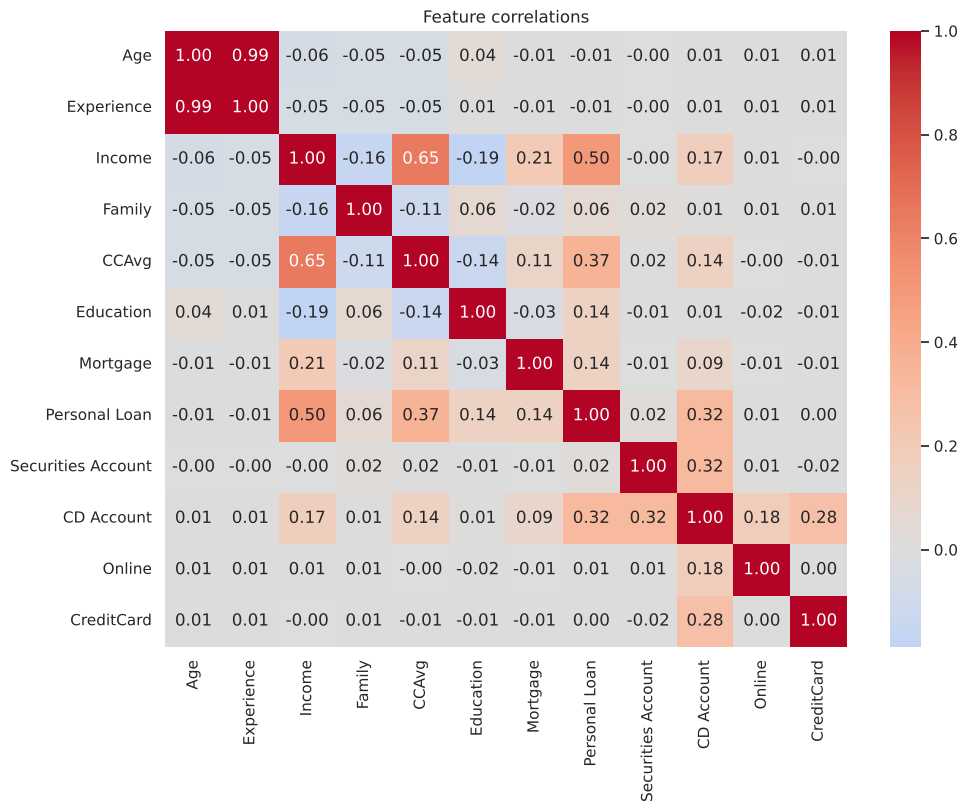

Income                0.502462
CCAvg                 0.366889
CD Account            0.316355
Mortgage              0.142095
Education             0.136722
Family                0.061367
Securities Account    0.021954
Online                0.006278
CreditCard            0.002802
Experience           -0.007413
Age                  -0.007726
Name: Personal Loan, dtype: float64

In [9]:
plt.figure(figsize=(11, 8))
sns.heatmap(df.drop(columns=['ID', 'ZIP Code']).corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Feature correlations'); plt.show()
df.drop(columns=['ID', 'ZIP Code']).corr()[TARGET].drop(TARGET).sort_values(ascending=False)

## 2. Preprocessing
1. Drop `ID`, `ZIP Code`
2. Clip negative `Experience` to 0
3. **Stratified** 80/20 train/test split (keeps 9.6% positives in both)
4. `StandardScaler` fitted on **train only** (inside each Pipeline in the improved models, so CV folds never see test or validation statistics)

In [10]:
data = clean_data(df)
X, y = split_xy(data)
X_train, X_test, y_train, y_test = train_test(X, y)
print('Train:', X_train.shape, 'positive rate %.3f' % y_train.mean())
print('Test :', X_test.shape, 'positive rate %.3f' % y_test.mean())
print('Min Experience after cleaning:', data['Experience'].min())

Train: (4000, 11) positive rate 0.096
Test : (1000, 11) positive rate 0.096
Min Experience after cleaning: 0


## 3. Experiment 1 – Baseline (replicating the paper)
Same model families as the paper with default settings: Perceptron, Logistic Regression, KNN, linear SVM on **unscaled** features; K-Means (k=2, clusters mapped to majority label) and MLP (one hidden layer of 100 neurons) on scaled features. No imbalance handling.

In [11]:
from train import run_baseline, run_improved
base = run_baseline(X_train, X_test, y_train, y_test)
base


=== Experiment 1: Baseline (paper replication) ===


                     Accuracy  Precision  Recall      F1  ROC_AUC
Model                                                            
Perceptron              0.911     0.7059  0.1250  0.2124   0.7890
Logistic Regression     0.952     0.8077  0.6562  0.7241   0.9637
KNN                     0.905     0.5082  0.3229  0.3949   0.8755
Linear SVM              0.956     0.8611  0.6458  0.7381   0.9624
K-Means (k=2)           0.904     0.0000  0.0000  0.0000   0.5163
MLP (100 neurons)       0.987     0.9192  0.9479  0.9333   0.9957


,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Perceptron,0.911,0.7059,0.1250,0.2124,0.7890
Logistic Regression,0.952,0.8077,0.6562,0.7241,0.9637
KNN,0.905,0.5082,0.3229,0.3949,0.8755
Linear SVM,0.956,0.8611,0.6458,0.7381,0.9624
K-Means (k=2),0.904,0.0000,0.0000,0.0000,0.5163
MLP (100 neurons),0.987,0.9192,0.9479,0.9333,0.9957


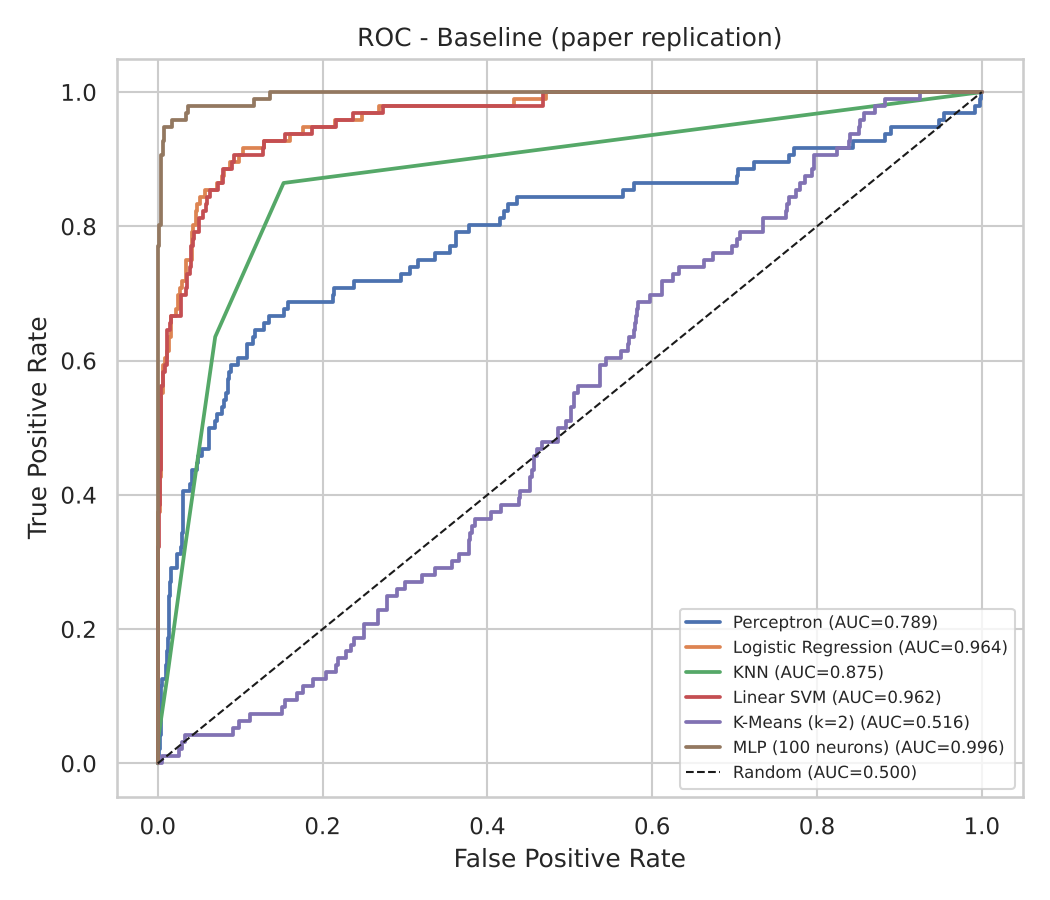

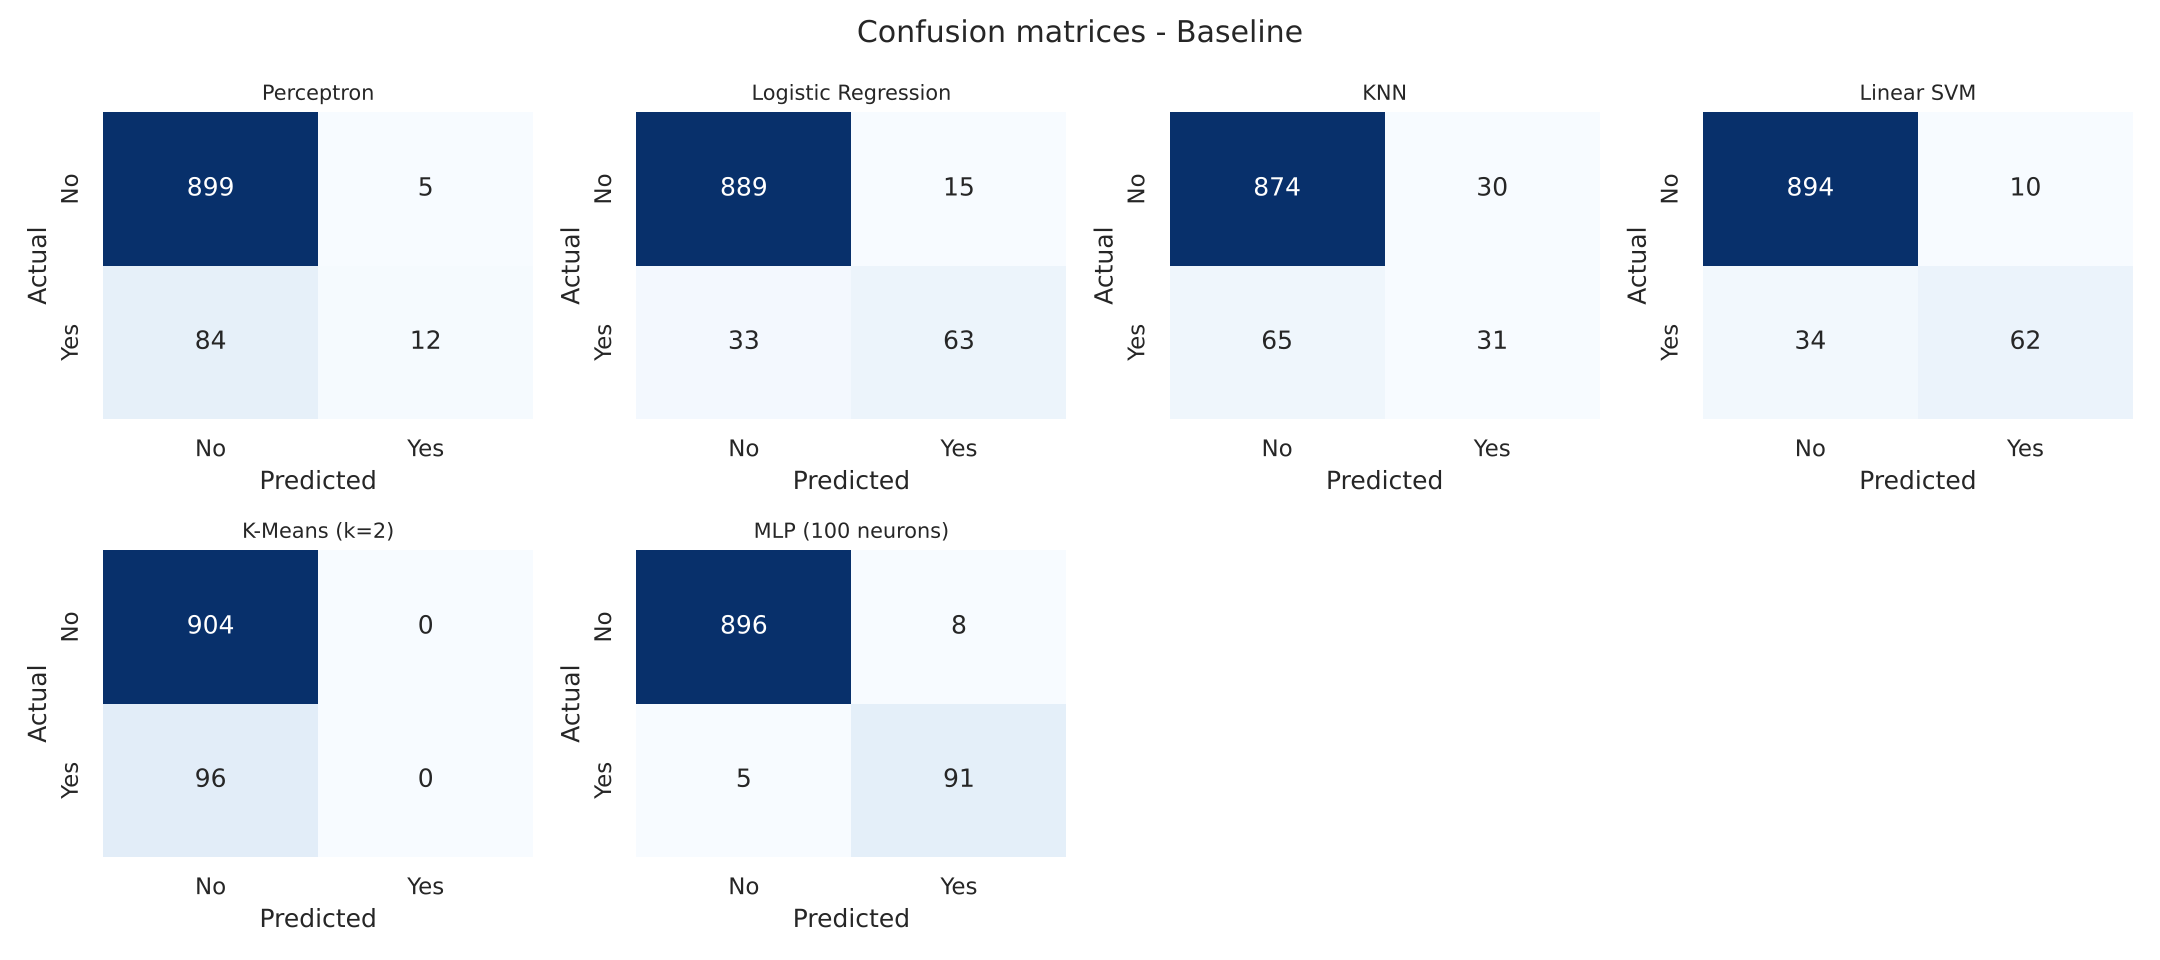

In [12]:
display(Image('../results/figures/roc_baseline.png', width=550))
display(Image('../results/figures/cm_baseline.png'))

**Baseline observations**
- High accuracy everywhere (~90–99%) but that hides the problem: the **Perceptron** catches only 12.5% of acceptors and **K-Means** predicts nobody (AUC ≈ 0.52, i.e. random) – the two natural clusters in the data are not the loan/no-loan split.
- Unscaled KNN is poor (F1 0.39) because distance is dominated by Income/Mortgage.
- The MLP (scaled) is already strong (F1 0.93, AUC 0.996), matching the paper's finding that the MLP is the best of these models.

## 4. Experiment 2 – Improved models
- Every model is a **Pipeline**: `StandardScaler → (SMOTE) → classifier`
- **Imbalance:** `class_weight='balanced'` (Perceptron, LR, SVM, RF), `scale_pos_weight` (XGBoost), **SMOTE** inside the pipeline for KNN and MLP (oversampling only the training folds)
- **Tuning:** `GridSearchCV`, 5-fold **stratified** CV, scoring = **F1**
- **New models:** Random Forest and XGBoost (non-linear, capture interactions like Income × Education)
- Best model chosen on **cross-validated F1**, not on the test set

In [13]:
imp, fitted, params = run_improved(X_train, X_test, y_train, y_test)
imp


=== Experiment 2: Improved (scaling + imbalance handling + tuning) ===


  Perceptron           CV-F1=0.5457  (1.9s)  {'alpha': 0.0001, 'penalty': None}


  Logistic Regression  CV-F1=0.6172  (0.3s)  {'C': 0.01}


  KNN + SMOTE          CV-F1=0.7745  (1.4s)  {'n_neighbors': 5, 'weights': 'distance'}


  SVM                  CV-F1=0.8405  (12.7s)  {'C': 10, 'kernel': 'rbf'}


  MLP + SMOTE          CV-F1=0.8546  (17.1s)  {'alpha': 0.0001, 'hidden_layer_sizes': [64, 32]}


  Random Forest        CV-F1=0.9197  (22.3s)  {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 400}


  XGBoost              CV-F1=0.9273  (5.1s)  {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 400, 'scale_pos_weight': 9.4}
                     Accuracy  Precision  Recall      F1  ROC_AUC   CV_F1
Model                                                                    
Perceptron              0.877     0.4270  0.8229  0.5623   0.9314  0.5457
Logistic Regression     0.891     0.4660  0.9271  0.6202   0.9626  0.6172
KNN + SMOTE             0.959     0.7200  0.9375  0.8145   0.9675  0.7745
SVM                     0.969     0.7876  0.9271  0.8517   0.9918  0.8405
MLP + SMOTE             0.975     0.8381  0.9167  0.8756   0.9941  0.8546
Random Forest           0.987     0.9029  0.9688  0.9347   0.9987  0.9197
XGBoost                 0.989     0.9126  0.9792  0.9447   0.9990  0.9273


,Accuracy,Precision,Recall,F1,ROC_AUC,CV_F1
Model,,,,,,
Perceptron,0.877,0.4270,0.8229,0.5623,0.9314,0.5457
Logistic Regression,0.891,0.4660,0.9271,0.6202,0.9626,0.6172
KNN + SMOTE,0.959,0.7200,0.9375,0.8145,0.9675,0.7745
SVM,0.969,0.7876,0.9271,0.8517,0.9918,0.8405
MLP + SMOTE,0.975,0.8381,0.9167,0.8756,0.9941,0.8546
Random Forest,0.987,0.9029,0.9688,0.9347,0.9987,0.9197
XGBoost,0.989,0.9126,0.9792,0.9447,0.9990,0.9273


In [14]:
pd.DataFrame(params).T

,alpha,penalty,C,n_neighbors,weights,kernel,hidden_layer_sizes,max_depth,min_samples_leaf,n_estimators,learning_rate,scale_pos_weight
Perceptron,0.0001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Logistic Regression,NaN,NaN,0.01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
KNN + SMOTE,NaN,NaN,NaN,5,distance,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SVM,NaN,NaN,10,NaN,NaN,rbf,NaN,NaN,NaN,NaN,NaN,NaN
MLP + SMOTE,0.0001,NaN,NaN,NaN,NaN,NaN,"[64, 32]",NaN,NaN,NaN,NaN,NaN
Random Forest,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,400.0,NaN,NaN
XGBoost,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.0,NaN,400.0,0.05,9.4


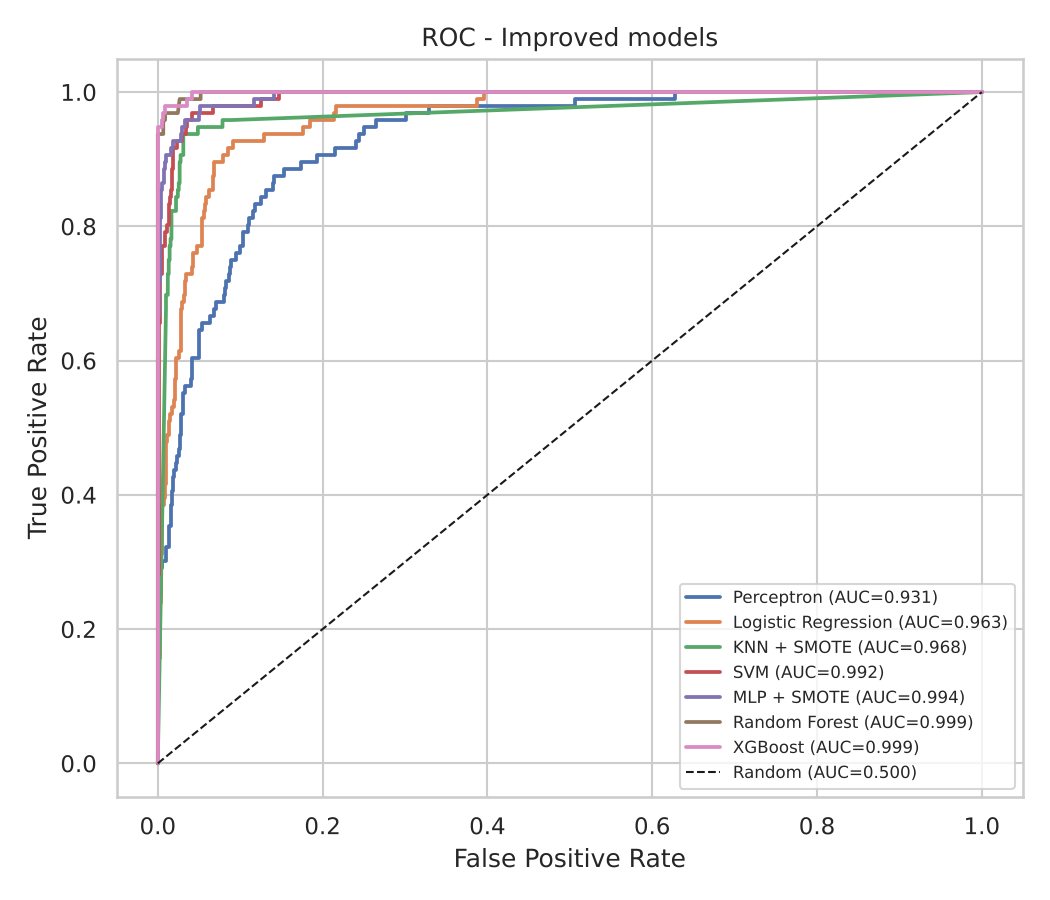

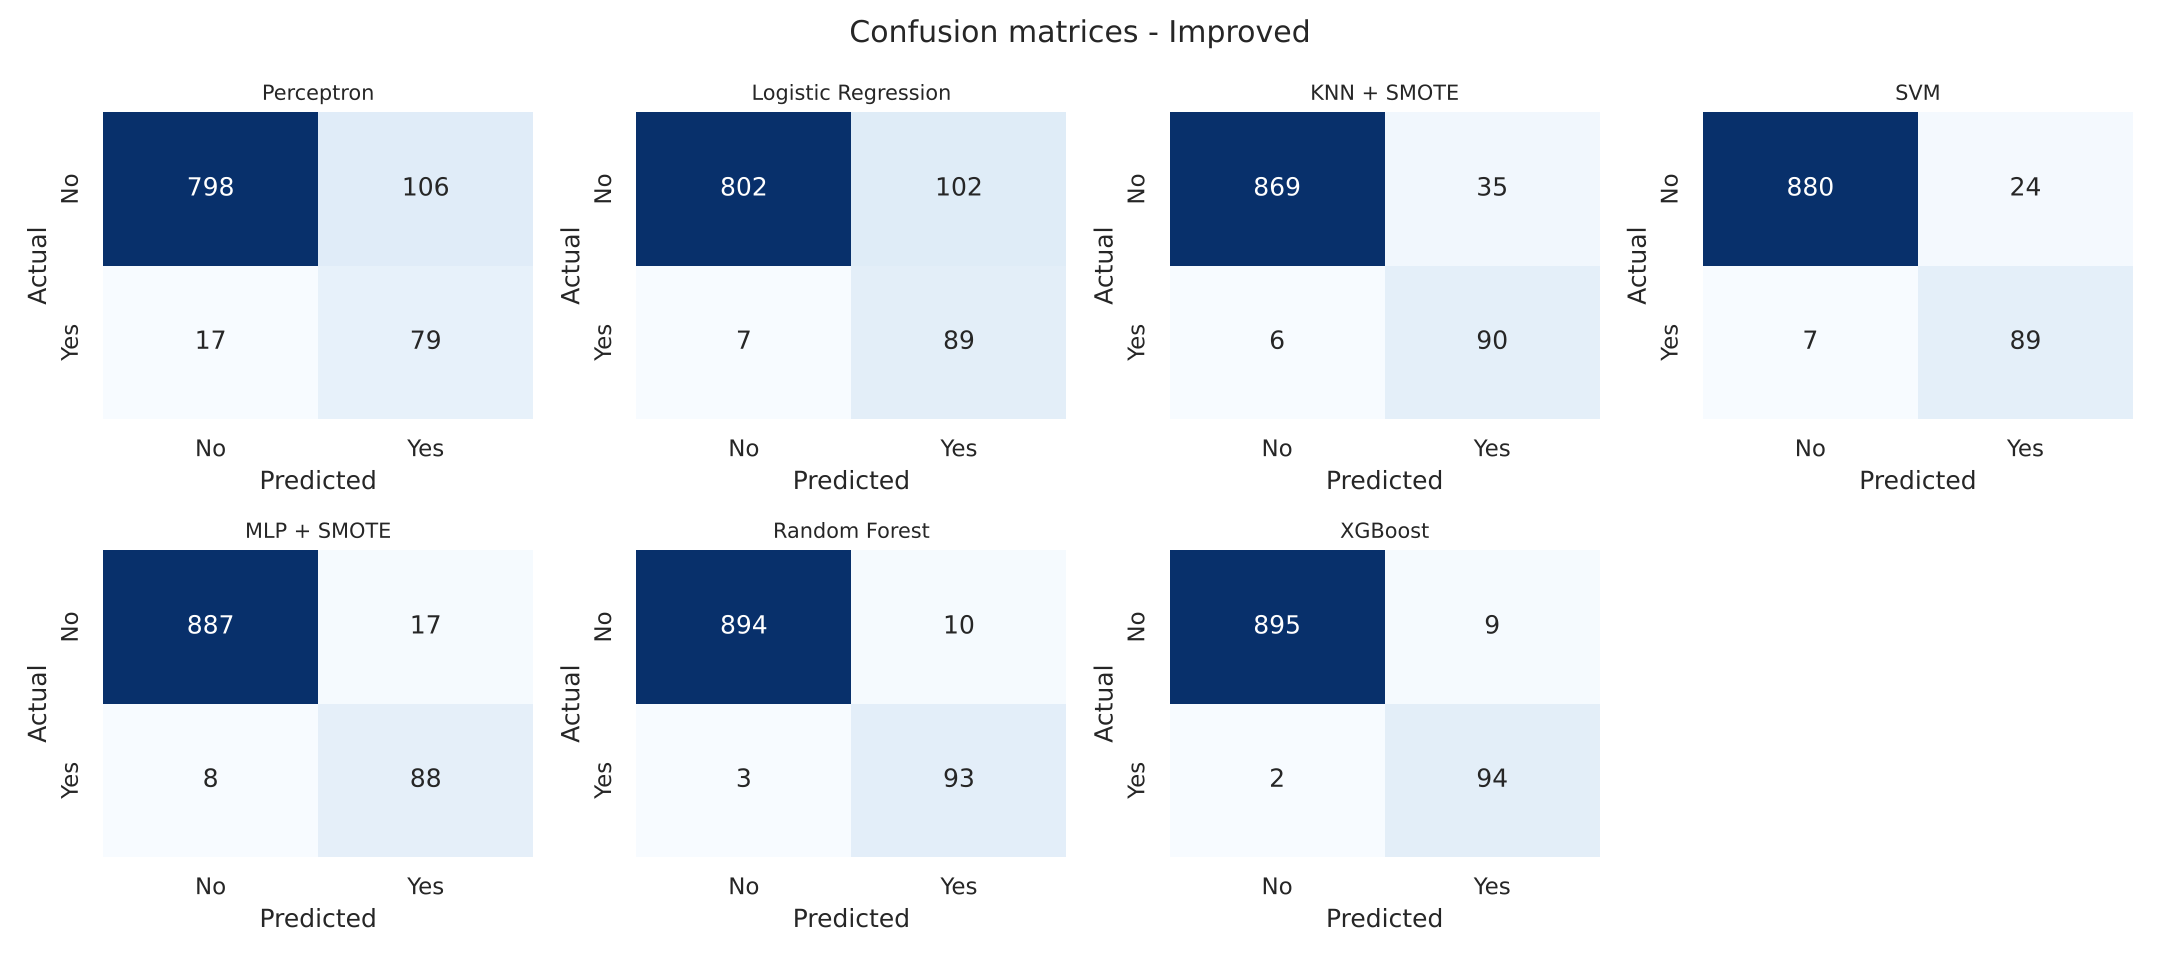

In [15]:
display(Image('../results/figures/roc_improved.png', width=550))
display(Image('../results/figures/cm_improved.png'))

### 4.1 Feature importance

Random Forest {'Income': 0.478, 'CCAvg': 0.207, 'Education': 0.105, 'Family': 0.067, 'CD Account': 0.048}


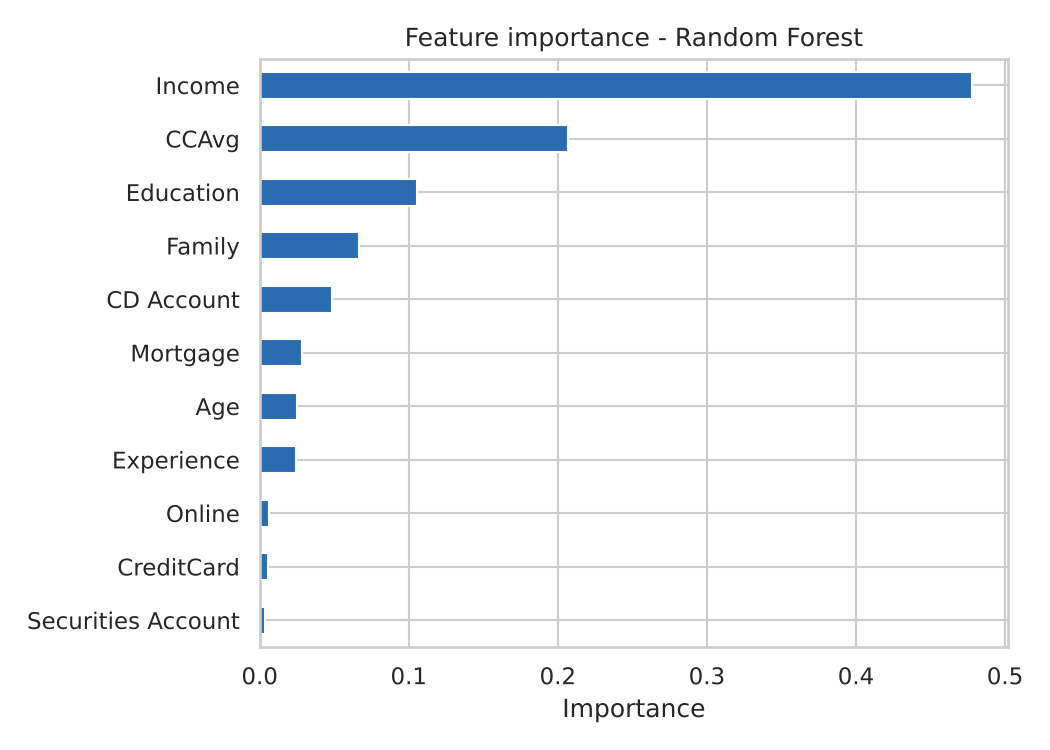

XGBoost {'Income': 0.4650000035762787, 'Family': 0.16699999570846558, 'Education': 0.14900000393390656, 'CCAvg': 0.07500000298023224, 'CD Account': 0.032999999821186066}


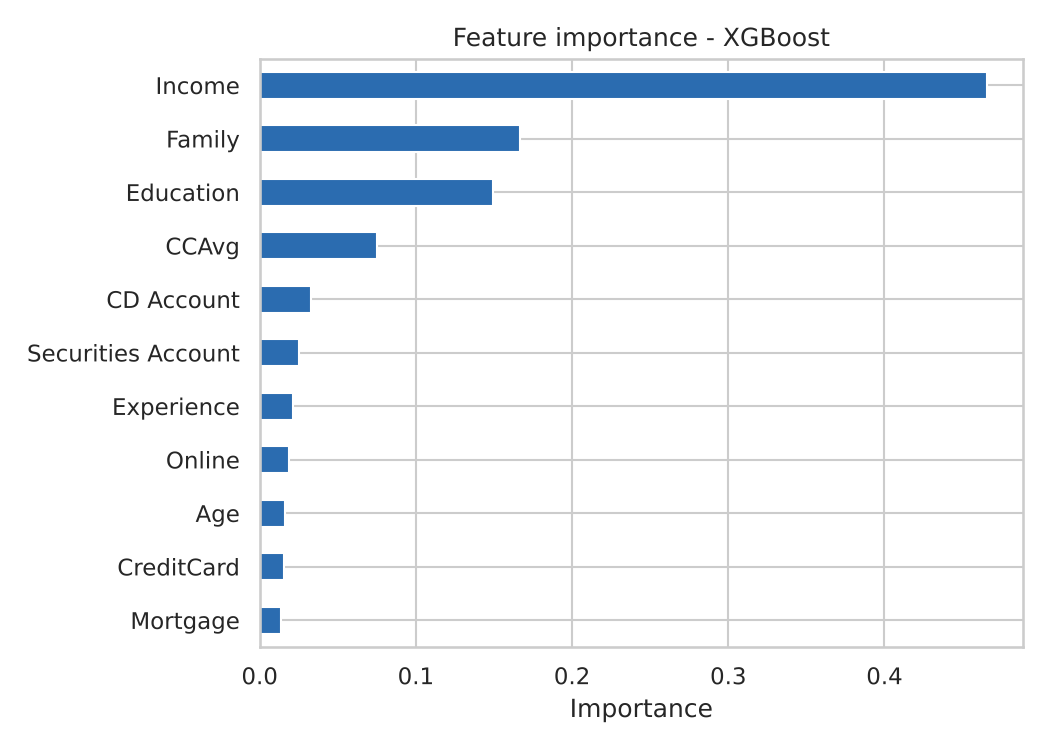

In [16]:
from evaluate import plot_feature_importance
for name in ['Random Forest', 'XGBoost']:
    clf = fitted[name][0].named_steps['clf']
    fname = 'feature_importance_' + name.lower().replace(' ', '_') + '.png'
    s = plot_feature_importance(clf, X_train.columns, f'Feature importance - {name}', fname)
    print(name, s.head(5).round(3).to_dict())
    display(Image('../results/figures/' + fname, width=500))

## 5. Baseline vs Improved

In [17]:
cols = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC']
comp = base[cols].add_suffix(' (base)').join(imp[cols].add_suffix(' (improved)'), how='outer')
comp[['Recall (base)', 'Recall (improved)', 'F1 (base)', 'F1 (improved)', 'ROC_AUC (base)', 'ROC_AUC (improved)']]

,Recall (base),Recall (improved),F1 (base),F1 (improved),ROC_AUC (base),ROC_AUC (improved)
Model,,,,,,
K-Means (k=2),0.0000,NaN,0.0000,NaN,0.5163,NaN
KNN,0.3229,NaN,0.3949,NaN,0.8755,NaN
KNN + SMOTE,NaN,0.9375,NaN,0.8145,NaN,0.9675
Linear SVM,0.6458,NaN,0.7381,NaN,0.9624,NaN
Logistic Regression,0.6562,0.9271,0.7241,0.6202,0.9637,0.9626
MLP (100 neurons),0.9479,NaN,0.9333,NaN,0.9957,NaN
MLP + SMOTE,NaN,0.9167,NaN,0.8756,NaN,0.9941
Perceptron,0.1250,0.8229,0.2124,0.5623,0.7890,0.9314
Random Forest,NaN,0.9688,NaN,0.9347,NaN,0.9987


In [18]:
import joblib
best_name = imp['CV_F1'].idxmax()
joblib.dump({'model': fitted[best_name][0], 'features': list(X_train.columns), 'name': best_name},
            '../models/best_model.pkl')
print('Best model by CV F1:', best_name)
imp.loc[best_name]

Best model by CV F1: XGBoost


Accuracy     0.9890
Precision    0.9126
Recall       0.9792
F1           0.9447
ROC_AUC      0.9990
CV_F1        0.9273
Name: XGBoost, dtype: float64

## 6. Conclusions
- **Best model: XGBoost** – F1 0.945, recall 0.979, ROC-AUC 0.999 on the held-out test set (only 2 of 96 acceptors missed, 9 false alarms). Random Forest is a close second.
- **Income** is the dominant predictor, followed by **Family**, **Education** and **CCAvg**; CD Account also matters. Age, Experience, Online and CreditCard contribute little.
- **Scaling** matters for distance/gradient models: KNN F1 went 0.39 → 0.81 and Perceptron recall 0.13 → 0.82.
- **Imbalance handling is a trade-off**: class weighting pushes recall of linear models above 0.92 but lowers precision (more false positives), so their F1 does not always rise. For a marketing campaign high recall is usually preferred (missing a likely customer costs more than one extra call).
- Linear models plateau around AUC 0.96 because the decision boundary is non-linear (e.g. high income **and** graduate education). Tree ensembles capture these interactions and are the clear winners.
- K-Means is not suitable: unsupervised clusters do not align with loan acceptance (AUC ≈ 0.52).

**Future work:** probability-threshold tuning to the bank's cost of a call vs a missed customer, SHAP explanations, testing on newer / larger bank data.